# 6. Spatial correlation and where to place samples
> Gaussian random fields as synthetic contamination, how random, stratified, systematic and clustered placement within a unit change what samples tell us, and what a directional plume adds

Background for the temporary series on the `scoring-experiments` branch:

0. A primer on Bayesian statistics, for trufl
1. A sampling campaign, round by round
2. The MCDM layer
3. What a good campaign means
4. The sawtooth in the restriction rule
5. From `bayes` to `voi`
6. Spatial correlation and where to place samples (this notebook)
7. Costs, dilemmas and a health limit

`_explain_overview.ipynb` summarises the design.

Notebooks 0 to 5 decide how many samples each unit gets. This one is about where the samples go inside a unit, first on fields that look the same in every direction, then on directional fields and a plume. The results behind it are in "Placement within a unit", "Directional fields" and "A synthetic plume" in `_scoring_experiments.ipynb`, and in `scoring-design.md`.

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, rotate, map_coordinates
from scipy.spatial.distance import pdist
from scipy.cluster.vq import kmeans2

## Why spatial correlation

Contamination after an accident is not scattered cell by cell. A plume deposits more where it passed and where it rained, so neighbouring fields have similar values and distant ones less so. This is spatial correlation: the closer two places, the more alike their values.

To test sampling strategies, we need fields with this property whose truth we know completely. Gaussian random fields are the simplest such model.

## A Gaussian random field

A Gaussian random field gives every cell a value such that any set of cells has a joint normal distribution. With a mean of 0 and a variance of 1, it is defined by one function: the correlation between two cells as a function of the distance `h` between them. The distance over which the correlation fades is the range.

The simplest way to make one is to smooth white noise. White noise gives each cell an independent normal value, so it has no correlation at all. A Gaussian filter of width `sigma` replaces each cell by a weighted average of the noise around it. Two cells closer than a few `sigma` average over much of the same noise, so they get similar values. Two cells far apart average over different noise, so they stay independent.

In [ ]:
def grf(sigma, rng, N=128):
    "An `N` by `N` Gaussian random field with mean 0 and variance 1, white noise smoothed with width `sigma` cells."
    z = rng.standard_normal((N, N))
    f = gaussian_filter(z, sigma, mode='wrap') if sigma > 0 else z
    return (f - f.mean()) / f.std()

`mode='wrap'` treats the grid as a torus, so cells at the edges are smoothed like the others. The last line rescales the field to a mean of 0 and a variance of 1, because smoothing shrinks the variance. Three fields from the same noise, with increasing `sigma`:

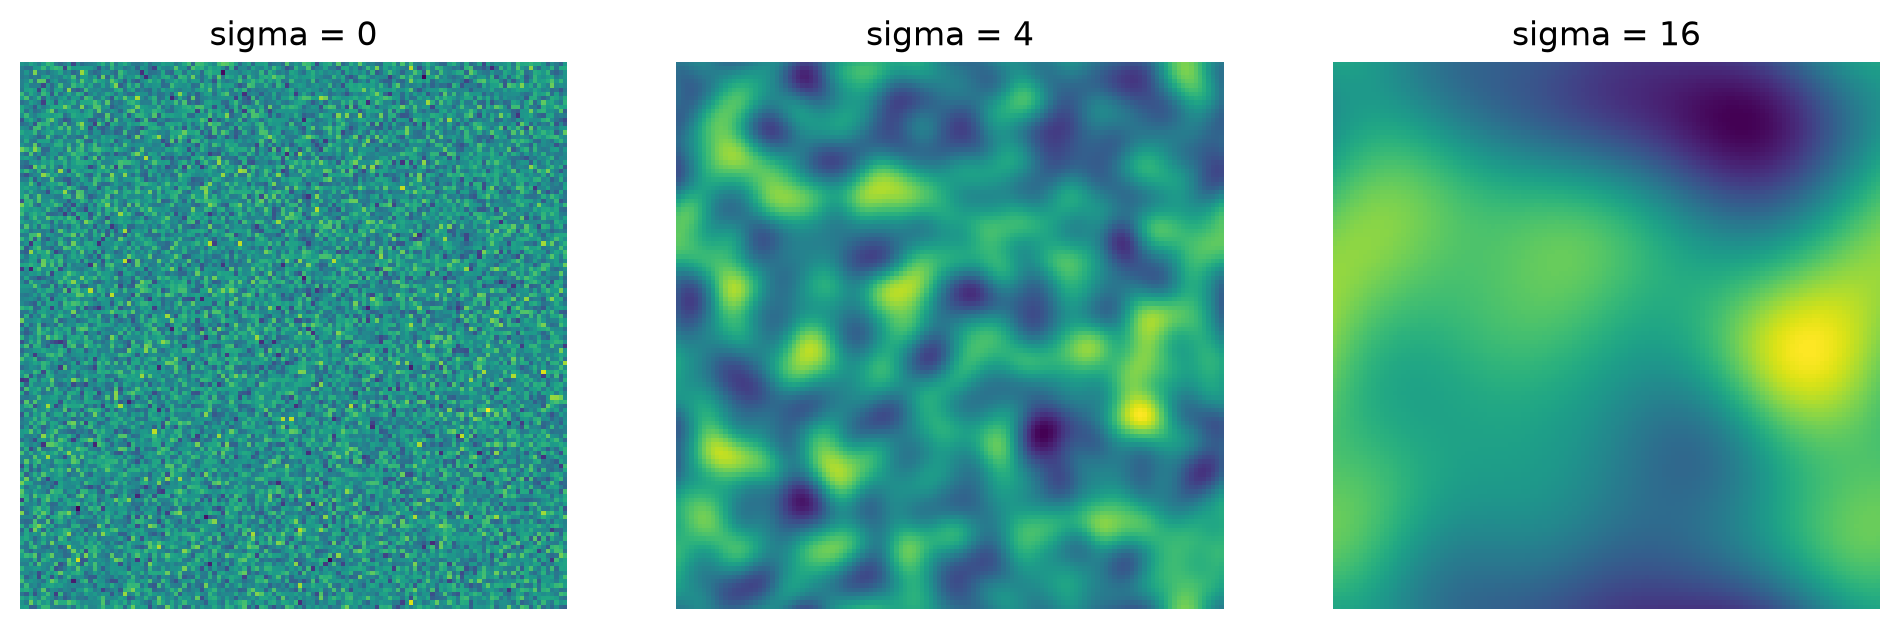

In [ ]:
rng = np.random.default_rng(0)
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
for ax, s in zip(axs, [0, 4, 16]):
    ax.imshow(grf(s, np.random.default_rng(0)), cmap='viridis'); ax.set_title(f'sigma = {s}'); ax.axis('off')

With `sigma` 0 it is pure noise. With 4, small patches appear. With 16, the patches are about as wide as a quarter of the grid.

Smoothing with a Gaussian of width `sigma` gives a correlation of exp(-h² / 4 sigma²) at distance `h`. The check below measures it on large fields, so that the finite grid does not bias it, and compares with the formula:

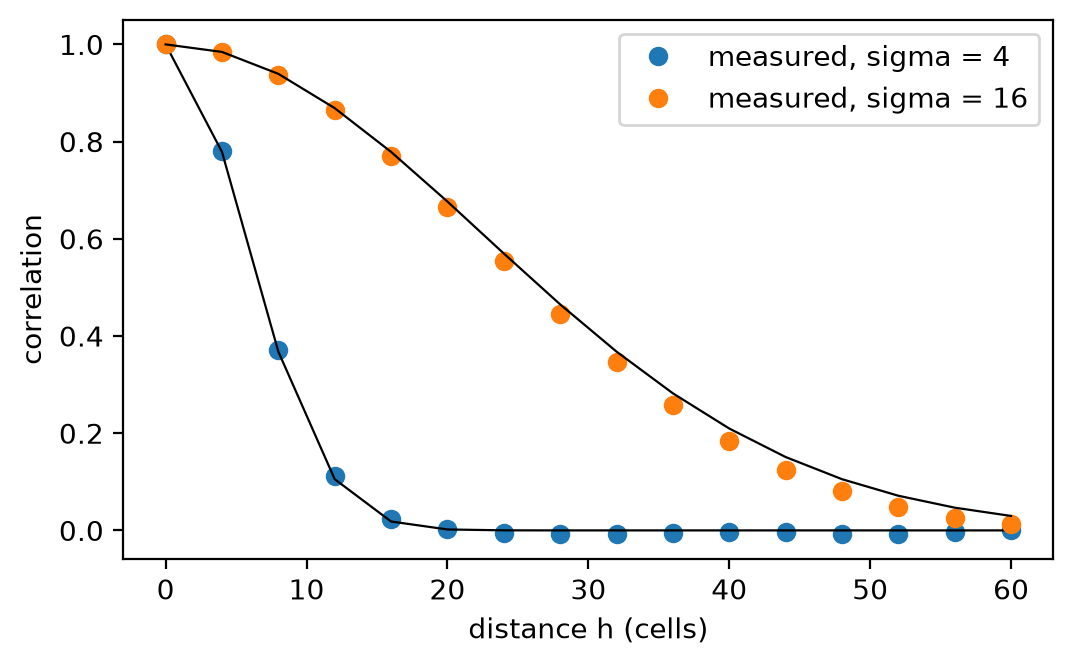

In [ ]:
def corr_at(sigma, lags, reps=10, N=512, seed=0):
    "Correlation between cells `lags` apart along a row, averaged over `reps` fields."
    rng = np.random.default_rng(seed); out = np.zeros(len(lags))
    for _ in range(reps):
        f = grf(sigma, rng, N)
        out += [np.mean(f * np.roll(f, h, axis=1)) for h in lags]
    return out / reps

lags = np.arange(0, 61, 4)
fig, ax = plt.subplots(figsize=(6, 3.5))
for s in [4, 16]:
    c = corr_at(s, lags)
    ax.plot(lags, c, 'o', label=f'measured, sigma = {s}'); ax.plot(lags, np.exp(-lags**2 / (4 * s**2)), 'k-', lw=0.8)
    assert np.abs(c - np.exp(-lags**2 / (4 * s**2))).max() < 0.05
ax.set_xlabel('distance h (cells)'); ax.set_ylabel('correlation'); ax.legend();

The correlation falls to about 5% at h = 3.5 sigma: 14 cells for `sigma` 4 and 56 cells for `sigma` 16. On a unit of 128 cells, the first field holds many independent patches and the second only a few.

Smoothing gives this Gaussian-shaped correlation only. Geostatistics also uses exponential and Matérn correlations, which are rougher at short distances; they are made by filtering the noise in Fourier space instead. For sampling questions, the range compared with the size of the unit matters most, so smoothing is enough here.

Measured contamination is closer to lognormal than normal. `np.exp(a + b * grf(...))` gives a lognormal field with the same pattern. Since the level below is set by a quantile, the share above it and every result in this notebook stay the same under that transform.

## A contaminated unit

Take the whole grid as one unit. Setting the level at the 90% quantile of the field makes exactly 10% of the unit's area exceed it, so the truth trufl wants to know, `share`, is fixed and known:

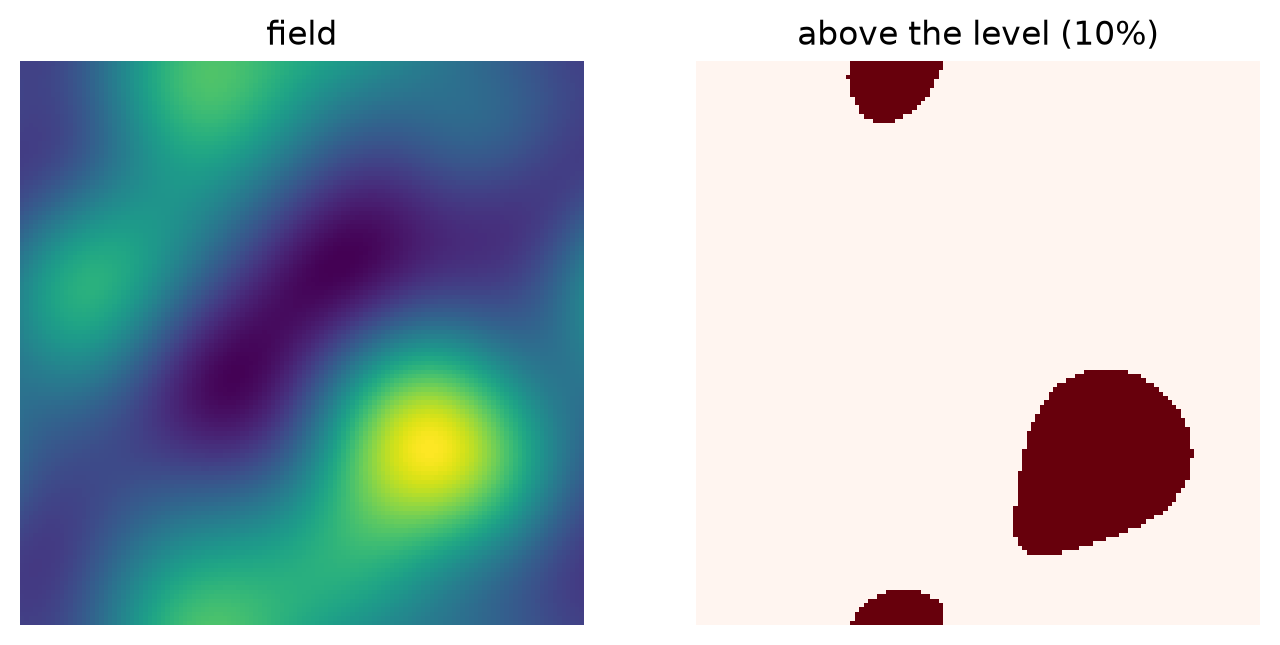

In [ ]:
p = 0.10
f = grf(16, np.random.default_rng(3))
level = np.quantile(f, 1 - p)
above = f > level
assert abs(above.mean() - p) < 1e-3
fig, axs = plt.subplots(1, 2, figsize=(8, 4))
axs[0].imshow(f, cmap='viridis'); axs[0].set_title('field')
axs[1].imshow(above, cmap='Reds'); axs[1].set_title('above the level (10%)')
for ax in axs: ax.axis('off')

With correlation, the 10% above the level forms a few patches instead of scattered cells. Where samples land relative to the patches now matters.

## Four placements

Each placement returns the row and column of `n` samples in an `N` by `N` unit:

- Random: each sample is a uniform random cell, independently of the others.
- Stratified: cut the unit into `n` equal blocks and draw one random cell in each. The samples are spread out, but each is still random within its block.
- Systematic: a regular grid of `n` points, shifted as a whole by one random offset. The spacing is fixed; only the offset is random.
- Clustered: samples gathered around 4 random centres, as when teams sample along roads or at one farm.

In [ ]:
def place(design, n, rng, N=128):
    "Row and column of `n` samples placed by `design` in an `N` by `N` unit; `n` must be a square for the grid designs."
    if design == 'random': return rng.integers(0, N, (n, 2))
    s = int(round(np.sqrt(n))); w = N / s
    gi, gj = np.meshgrid(np.arange(s), np.arange(s)); g = np.c_[gi.ravel(), gj.ravel()]
    if design == 'stratified': return np.floor((g + rng.random((n, 2))) * w).astype(int)
    if design == 'systematic': return np.floor((g + rng.random(2)) * w).astype(int)
    if design == 'clustered':
        c = rng.integers(0, N, (4, 2))
        return (c[np.arange(n) % 4] + rng.integers(-6, 7, (n, 2))) % N

designs = ['random', 'stratified', 'systematic', 'clustered']

In stratified placement, `g` holds the block indices and `rng.random((n, 2))` a separate position inside each block. In systematic placement, `rng.random(2)` is one offset shared by all points. Thirty-six samples of each placement on the unit above:

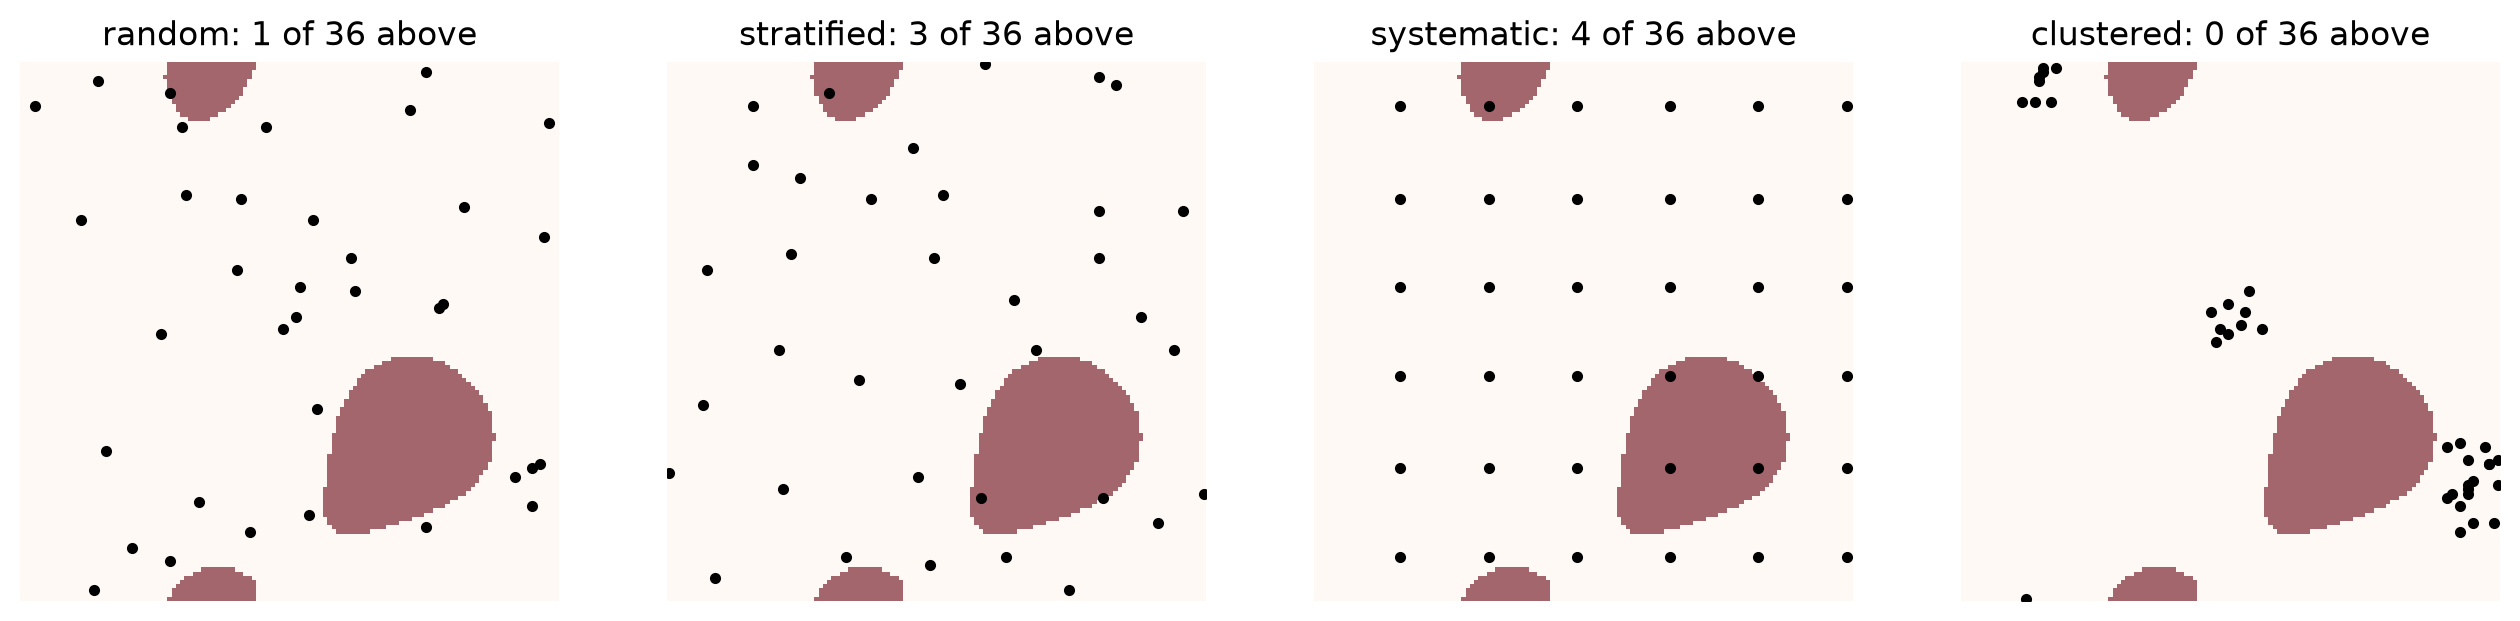

In [ ]:
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for ax, d in zip(axs, designs):
    xy = place(d, 36, np.random.default_rng(1))
    k = above[xy[:, 0], xy[:, 1]].sum()
    ax.imshow(above, cmap='Reds', alpha=0.6); ax.plot(xy[:, 1], xy[:, 0], 'k.', ms=6)
    ax.set_title(f'{d}: {k} of 36 above'); ax.axis('off')

Random samples can leave gaps and pile up elsewhere by chance. Stratified and systematic samples cover the unit evenly, so each patch gets about as many samples as its area deserves. Clustered samples see four places only.

## Why random placement keeps the binomial model

For random placement, each sample lands above the level with probability `share`, the fraction of the unit's area above it, whatever the pattern of the field. The samples are independent because the points are drawn independently, not because the field is uncorrelated. Survey statistics calls this design-based inference. It is why `bayes` and `voi` use a binomial model, and why that model is exact for random placement even on a correlated field.

Spread placements break the independence on purpose, in a useful direction: two samples are never close, so they rarely repeat each other's information. Clustered placement breaks it in the harmful direction: samples in one cluster mostly repeat each other.

## How much each placement tells

Repeat the experiment on many fields: draw a field with a true `share` of 10%, place `n` samples, count the samples above the level. The spread of `k / n` around 0.10 shows how well each placement estimates `share`:

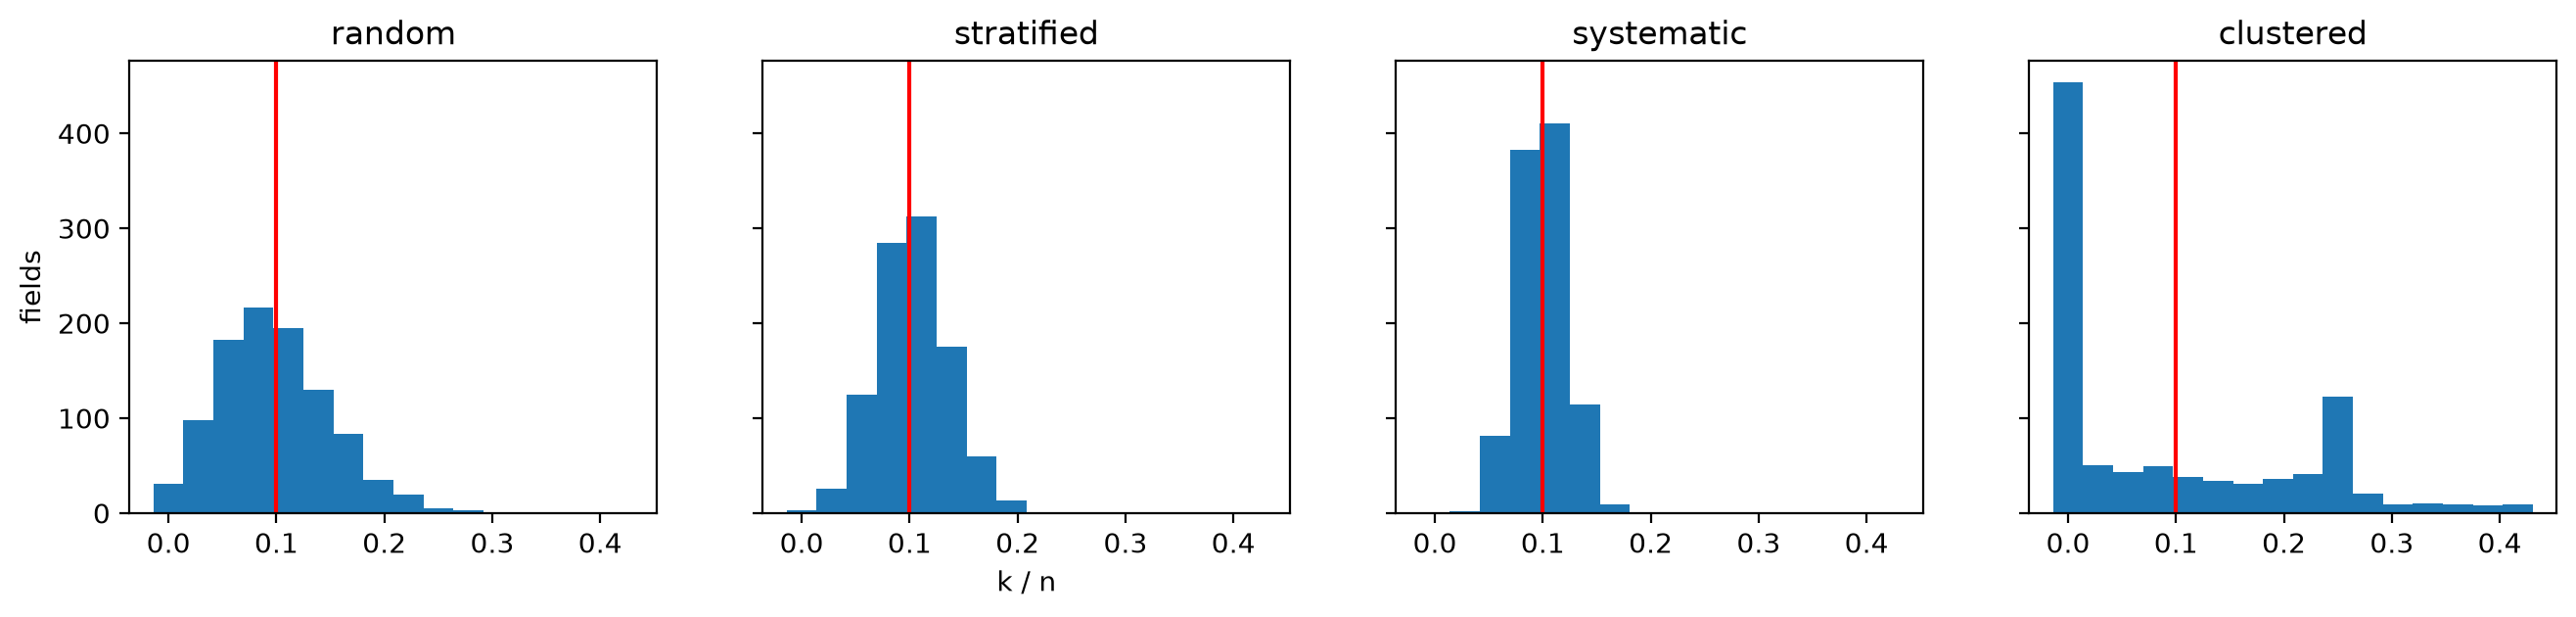

In [ ]:
def exceedances(sigma, p, design, n, reps=1000, seed=0):
    "Number of samples above the level in `reps` fields with a true share `p` above it."
    rng = np.random.default_rng(seed); k = np.empty(reps)
    for r in range(reps):
        f = grf(sigma, rng); lvl = np.quantile(f, 1 - p)
        xy = place(design, n, rng); k[r] = (f[xy[:, 0], xy[:, 1]] > lvl).sum()
    return k

n = 36
ks = {d: exceedances(16, p, d, n) for d in designs}
fig, axs = plt.subplots(1, 4, figsize=(16, 3), sharey=True)
for ax, d in zip(axs, designs):
    ax.hist(ks[d] / n, bins=np.arange(-0.5, 16.5) / n, color='C0'); ax.axvline(p, color='r'); ax.set_title(d)
axs[0].set_ylabel('fields'); axs[1].set_xlabel('k / n');

The effective sample size turns a spread into a sample count: the number of random samples that would give the same variance. Random samples give p(1 - p) / n, so a placement with variance `var` is worth p(1 - p) / `var` random samples:

In [ ]:
n_eff = {d: p * (1 - p) / (ks[d] / n).var() for d in designs}
pd.Series(n_eff).round(0)

random         34.0
stratified     77.0
systematic    167.0
clustered       5.0
dtype: float64

In [ ]:
assert 25 < n_eff['random'] < 50
assert n_eff['systematic'] > 3 * n
assert n_eff['clustered'] < n / 4

With `sigma` 16, the 36 random samples are worth about 36, as the binomial model says. The 36 stratified samples are worth about twice as many, the 36 systematic ones more than four times as many, and the 36 clustered ones only a handful. `_scoring_experiments.ipynb` repeats this for other `sigma` and `n`: without correlation all placements are the same, and the gain from spreading grows with the range.

## Systematic or stratified

Systematic placement gained most here, but it has two weaknesses:

- Periodic patterns. If the field repeats with a period close to the grid spacing (terraces, rows of a crop, drainage lines), every point can fall on the same phase, and the estimate is biased. Stratified placement draws each point independently within its block, so it cannot lock onto a period.
- Uncertainty. With one random offset, a systematic sample has no unbiased estimate of its own variance. Treating it as random (binomial) is safe, because it overstates the uncertainty.

Stratified placement keeps part of the gain (77 against 167 here) and avoids both. It is the safer default when the field may have a period; systematic placement is the better one when it can't.

## Units that are not squares

Real units are municipalities or fields, not squares. Two simple ways to spread samples over any shape, given the cells inside the unit:

- Systematic: lay a regular grid with a random offset over the bounding box, and keep the points inside the unit. The number of points varies with the offset and the shape.
- Stratified: cut the unit's cells into `n` compact strata of similar size with k-means on their coordinates, and draw one random cell in each.

In [ ]:
N = 128
rows, cols = np.mgrid[:N, :N]
inside = ((cols - 60) / 55)**2 + ((rows - 64) / 35)**2 < 1
cells = np.c_[rows[inside], cols[inside]]

def stratified_in(cells, n, rng):
    "One random cell in each of `n` k-means strata of `cells`."
    _, lab = kmeans2(cells.astype(float), n, seed=rng, minit='++')
    return np.array([cells[rng.choice(np.flatnonzero(lab == j))] for j in range(n)]), lab

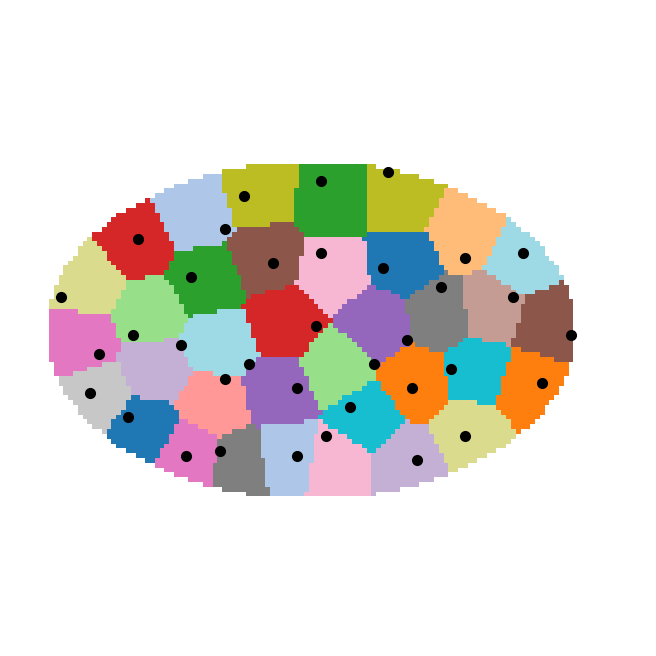

In [ ]:
rng = np.random.default_rng(2)
xy, lab = stratified_in(cells, 36, rng)
strata = np.full((N, N), np.nan); strata[inside] = lab
fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(strata, cmap='tab20', interpolation='nearest'); ax.plot(xy[:, 1], xy[:, 0], 'k.', ms=6); ax.axis('off');

Each colour is a stratum; each has one sample. For a large unit, k-means on every cell is slow; running it on a random subset of cells gives the same strata. Spatially balanced designs such as GRTS (generalised random tessellation stratified) do the same job with more guarantees, and are used in environmental monitoring.

## Estimating the range: variogram and Moran's I

How much spreading gains depends on the range compared with the unit. The usual estimate is a variogram: for each pair of samples, half the squared difference of their values, averaged in bins of distance. Close pairs have small differences when the range is long; beyond the range the semivariance levels off at the variance. Here are variograms from 64 random samples on five fields each, for two ranges:

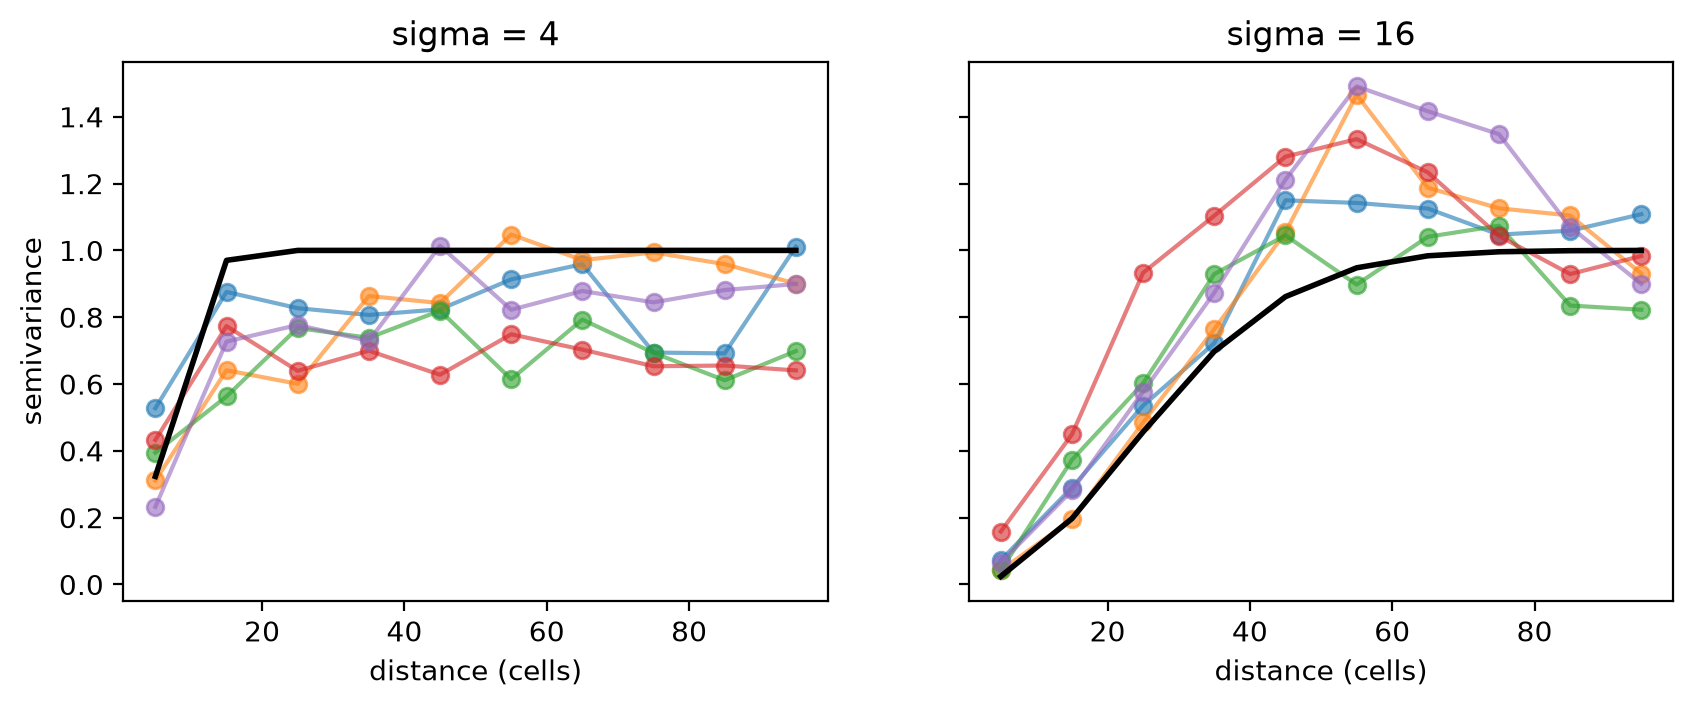

In [ ]:
def variogram(xy, z, bins):
    "Mean of half the squared difference of `z` over pairs of points in each distance bin."
    d, g = pdist(xy), 0.5 * pdist(z[:, None], 'sqeuclidean')
    i = np.digitize(d, bins)
    return np.array([g[i == j].mean() for j in range(1, len(bins))])

bins = np.arange(0, 101, 10); mids = bins[:-1] + 5
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, s in zip(axs, [4, 16]):
    rng = np.random.default_rng(1)
    for _ in range(5):
        f = grf(s, rng); xy = place('random', 64, rng)
        ax.plot(mids, variogram(xy, f[xy[:, 0], xy[:, 1]], bins), 'o-', alpha=0.6)
    ax.plot(mids, 1 - np.exp(-mids**2 / (4 * s**2)), 'k-', lw=2)
    ax.set_title(f'sigma = {s}'); ax.set_xlabel('distance (cells)')
axs[0].set_ylabel('semivariance');

With `sigma` 4, the semivariance is near its plateau from the first bin: samples more than 10 cells apart are nearly independent. With `sigma` 16, it climbs over about 40 cells. Sixty-four samples separate the two cases, but each curve is noisy, so the range from one unit is rough; pooling neighbouring units, or reading the scale from the prior raster, would do better.

Moran's I, which `MoranICB` computes, tests whether nearby samples are more alike than distant ones. It answers whether there is correlation, not over what distance, so it cannot say how much spreading gains.

## Directional fields

A plume spreads contamination along the wind. Along the plume axis, values change slowly. Across it, they change fast. In a Gaussian random field this is anisotropy: the range depends on direction.

To make an anisotropic field, smooth the noise with a different width along each axis of the array, then rotate the result to the plume direction. `aniso_field` smooths with `s_across` cells across the plume and `s_along` cells along it, rotates by `angle` degrees counterclockwise from east, and crops the centre so that the rotation leaves no empty corners.

In [ ]:
def aniso_field(rng, angle, s_across=4, s_along=16, N=128):
    "An `N` by `N` field with mean 0 and variance 1, range `s_along` along direction `angle` and `s_across` across it."
    z = gaussian_filter(rng.standard_normal((2 * N, 2 * N)), (s_across, s_along), mode='wrap')
    f = rotate(z, angle, reshape=False, order=1)[N // 2:N // 2 + N, N // 2:N // 2 + N]
    return (f - f.mean()) / f.std()

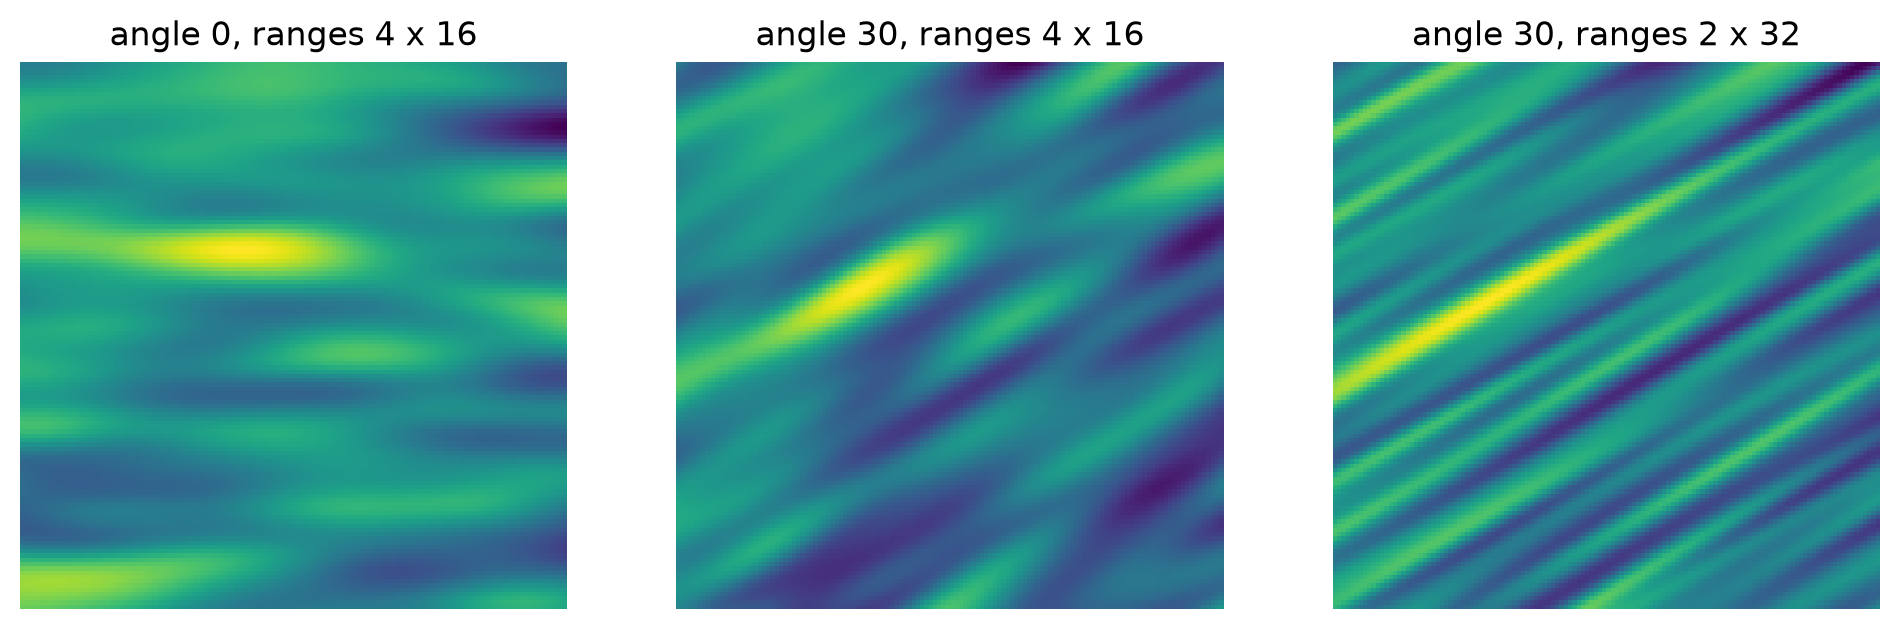

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
for ax, (a, sa, sl) in zip(axs, [(0, 4, 16), (30, 4, 16), (30, 2, 32)]):
    ax.imshow(aniso_field(np.random.default_rng(0), a, sa, sl), cmap='viridis')
    ax.set_title(f'angle {a}, ranges {sa} x {sl}'); ax.axis('off')

The patches are elongated along the direction `angle`. In the image, rows grow downwards, so 30° counterclockwise from east points up and to the right.

To check the direction, measure the correlation between each cell and the cell 12 cells away in a given direction. `corr_towards` does this for one field and one direction. Averaged over five fields, it is highest in the direction `angle`:

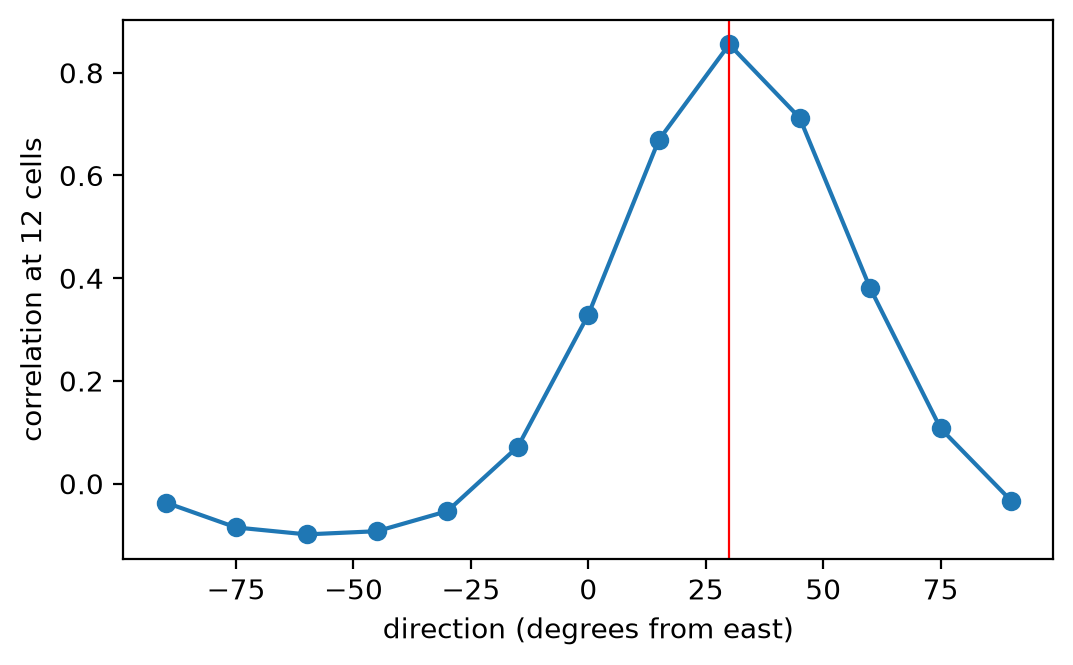

In [ ]:
def corr_towards(f, angle, h=12):
    "Correlation of the field `f` with itself shifted `h` cells towards `angle`."
    r, c = np.mgrid[20:108, 20:108]
    t = np.deg2rad(angle)
    g = map_coordinates(f, [r - h * np.sin(t), c + h * np.cos(t)], order=1)
    return np.corrcoef(f[20:108, 20:108].ravel(), g.ravel())[0, 1]

rng = np.random.default_rng(0)
fs = [aniso_field(rng, 30) for _ in range(5)]
dirs = np.arange(-90, 91, 15)
cs = np.array([np.mean([corr_towards(f, a) for f in fs]) for a in dirs])
assert dirs[cs.argmax()] == 30
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(dirs, cs, 'o-'); ax.axvline(30, color='r', lw=0.8)
ax.set_xlabel('direction (degrees from east)'); ax.set_ylabel('correlation at 12 cells');

At 12 cells, the correlation is 0.86 along the plume (30°). It falls to 0.67 at 15° off the axis, and to about 0 across the plume (120°, shown as -60°). With ranges 4 by 16, an error of 15° in the assumed direction already loses a fifth of the correlation.

### Directional variograms

The variogram above mixes all directions. A directional variogram keeps only the pairs of samples whose direction is close to a chosen one, here within 22.5°. Comparing the variogram along the plume with the one across it shows the anisotropy from samples. Here are both, from 100 random samples on each of five fields:

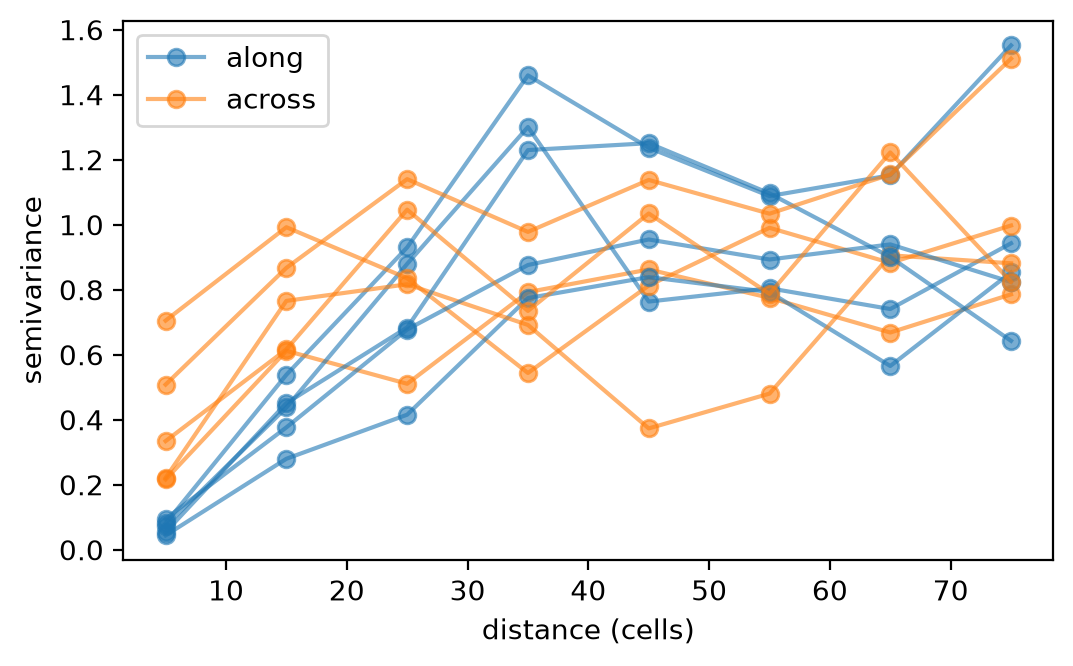

In [ ]:
def dir_variogram(xy, z, bins, angle, tol=22.5):
    "`variogram` using only the pairs whose direction is within `tol` degrees of `angle`."
    i, j = np.triu_indices(len(xy), 1)
    d = xy[j] - xy[i]
    pair_angle = np.degrees(np.arctan2(-d[:, 0], d[:, 1]))
    off = (pair_angle - angle + 90) % 180 - 90
    keep = np.abs(off) <= tol
    dist, g = np.hypot(*d[keep].T), 0.5 * (z[i] - z[j])[keep]**2
    k = np.digitize(dist, bins)
    return np.array([g[k == b].mean() if (k == b).any() else np.nan for b in range(1, len(bins))])

bins = np.arange(0, 81, 10); mids = bins[:-1] + 5
fig, ax = plt.subplots(figsize=(6, 3.5))
rng = np.random.default_rng(1)
for r in range(5):
    f = aniso_field(rng, 30); xy = rng.integers(0, 128, (100, 2)); z = f[xy[:, 0], xy[:, 1]]
    ax.plot(mids, dir_variogram(xy, z, bins, 30), 'C0o-', alpha=0.6, label='along' if r == 0 else None)
    ax.plot(mids, dir_variogram(xy, z, bins, 120), 'C1o-', alpha=0.6, label='across' if r == 0 else None)
ax.set_xlabel('distance (cells)'); ax.set_ylabel('semivariance'); ax.legend();

In `dir_variogram`, the row difference is negated because rows grow downwards. `off` folds each pair's direction into the range -90° to 90° around `angle`, because a pair has no front or back.

Averaged over the five fields, the semivariance along the plume rises from 0.07 at 5 cells to its plateau of about 1 at 35 cells. Across the plume it is already 0.4 at 5 cells and 0.77 at 15 cells. With 100 samples the two directions are clearly apart, though each single curve is noisy. In practice the direction comes from the wind record, a dispersion model or the survey, and a directional variogram checks it.

## Strata along the plume

The placements above spread samples evenly in every direction. With anisotropy, samples can be far apart along the plume, where neighbours repeat each other, but must be closer across it, where values change.

Stretched coordinates give this spacing. Rotate each cell's coordinates so that one axis follows the plume, then divide each axis by the range in that direction. In the stretched coordinates the field is isotropic. K-means strata that are compact there are elongated along the plume on the map.

In [ ]:
grid_rc = np.c_[np.mgrid[:128, :128][0].ravel(), np.mgrid[:128, :128][1].ravel()]

def along_across(rc, angle):
    "Coordinates of the (row, col) points `rc` along and across direction `angle`."
    t = np.deg2rad(angle)
    return -rc[:, 0] * np.sin(t) + rc[:, 1] * np.cos(t), rc[:, 0] * np.cos(t) + rc[:, 1] * np.sin(t)

def strata(n, angle=None, s_across=1, s_along=1, seed=0):
    "Cell indices of `n` k-means strata of the 128 by 128 unit, on raw coordinates or stretched along `angle`."
    x = grid_rc.astype(float)
    if angle is not None:
        along, across = along_across(x, angle)
        x = np.c_[along / s_along, across / s_across]
    _, lab = kmeans2(x, n, seed=seed, minit='++')
    return [np.flatnonzero(lab == j) for j in range(n)]

def draw(strata, rng):
    "Row and column of one random cell from each stratum."
    return grid_rc[[s[rng.integers(len(s))] for s in strata]]

`along_across` uses the same convention as `aniso_field`: angle counterclockwise from east, with rows growing downwards. Square strata, strata stretched along a plume at 30° with ranges 2 by 32, and the same strata stretched along the wrong axis (120°), with 36 samples each, over the cells of one such field above its 90% quantile:

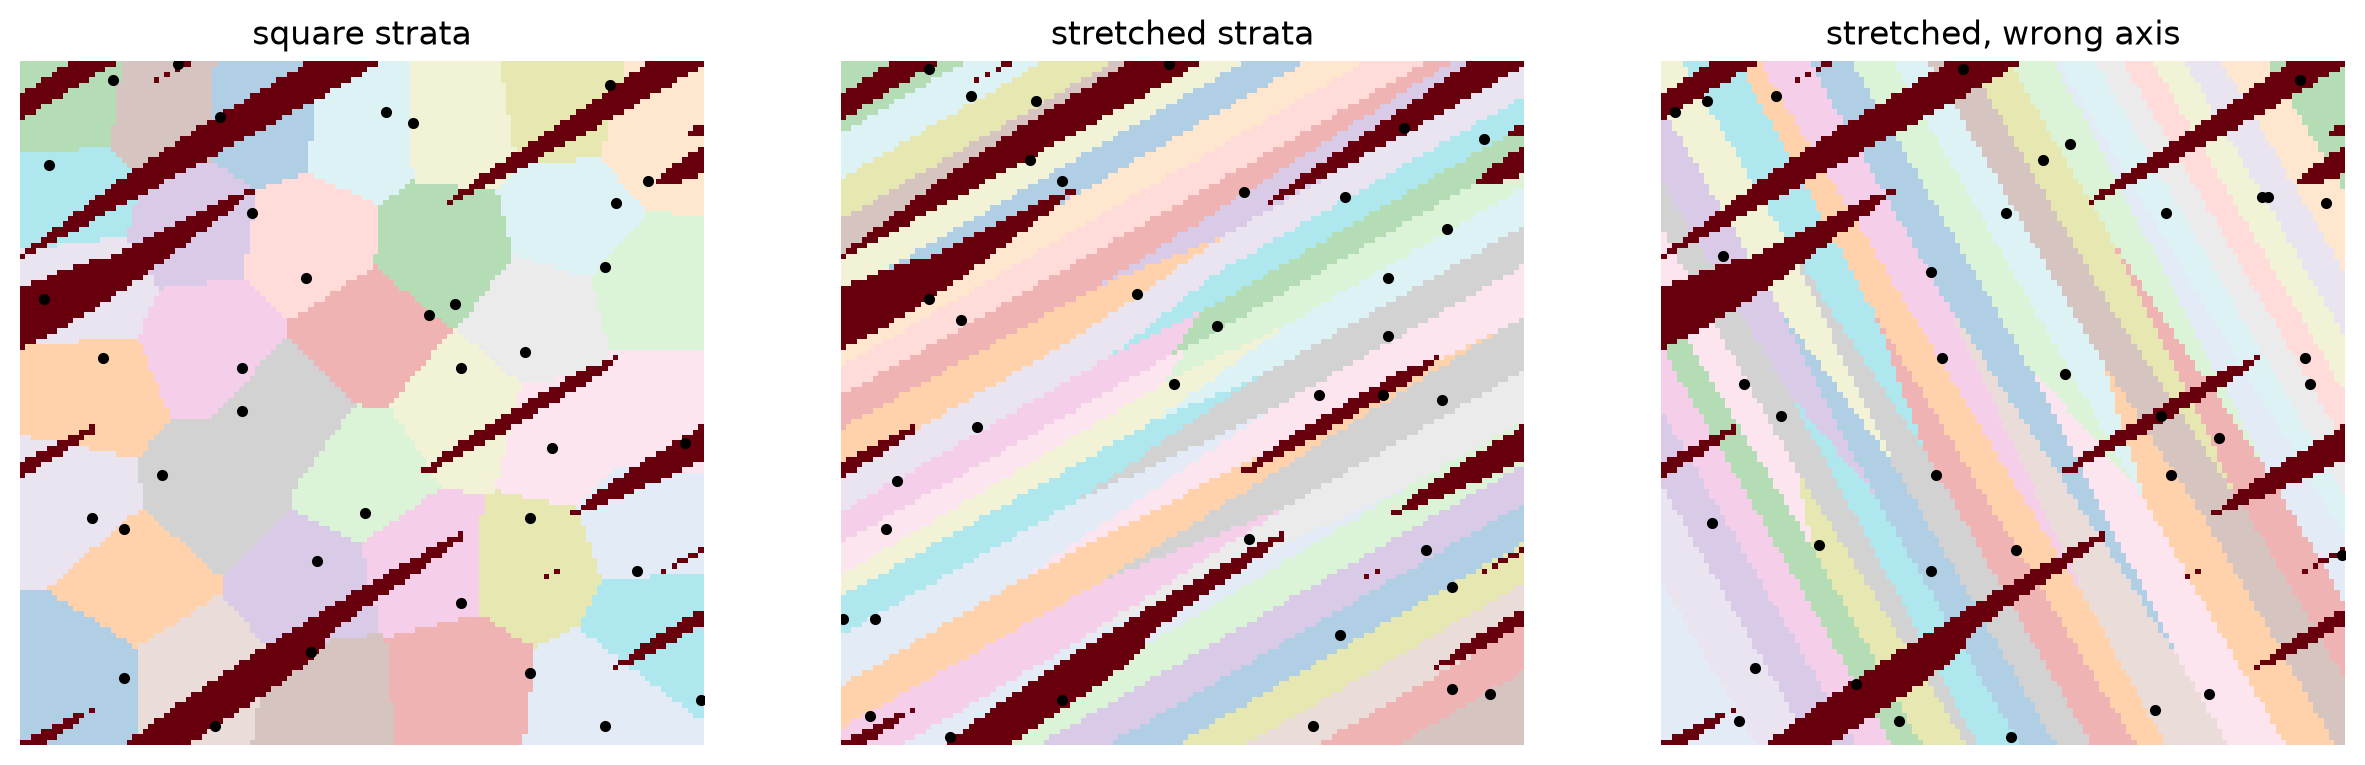

In [ ]:
f = aniso_field(np.random.default_rng(4), 30, 2, 32)
above = f > np.quantile(f, 0.9)
layouts = {'square strata': strata(36), 'stretched strata': strata(36, 30, 2, 32), 'stretched, wrong axis': strata(36, 120, 2, 32)}
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, S) in zip(axs, layouts.items()):
    lab = np.zeros(128 * 128)
    for j, s in enumerate(S): lab[s] = j
    ax.imshow(lab.reshape(128, 128), cmap='tab20', alpha=0.35, interpolation='nearest')
    ax.imshow(np.ma.masked_where(~above, above), cmap='Reds', vmin=0, vmax=1)
    xy = draw(S, np.random.default_rng(1)); ax.plot(xy[:, 1], xy[:, 0], 'k.', ms=6)
    ax.set_title(name); ax.axis('off')

The stretched strata are long and thin along the plume. Their samples are far apart along the plume and close together across it, which is the direction in which the patches above the level are narrow. Strata along the wrong axis do the opposite: their samples are close together along the plume, where they repeat each other, and far apart across it, where they miss patches.

The effective sample size of 36 samples on 1,000 such fields (ranges 2 by 32 at 30°, true share 10%):

In [ ]:
def aniso_exceedances(layouts, angle, s_across, s_along, n=36, reps=1000, p=0.1, seed=0):
    "Number of samples above the level for random placement and each of `layouts`, in `reps` fields with a true share `p`."
    rng = np.random.default_rng(seed)
    k = {d: np.empty(reps) for d in ['random', *layouts]}
    for r in range(reps):
        f = aniso_field(rng, angle, s_across, s_along); above = f > np.quantile(f, 1 - p)
        xy = rng.integers(0, 128, (n, 2)); k['random'][r] = above[xy[:, 0], xy[:, 1]].sum()
        for d, S in layouts.items(): xy = draw(S, rng); k[d][r] = above[xy[:, 0], xy[:, 1]].sum()
    return k

ka = aniso_exceedances(layouts, 30, 2, 32)
n_eff_aniso = pd.Series({d: 0.09 / (v / 36).var() for d, v in ka.items()})
n_eff_aniso.round(0)

random                   35.0
square strata            42.0
stretched strata         53.0
stretched, wrong axis    36.0
dtype: float64

In [ ]:
assert n_eff_aniso['stretched strata'] > n_eff_aniso['square strata'] > n_eff_aniso['stretched, wrong axis']

Square strata are worth 42 random samples, stretched strata 53, and strata along the wrong axis 36, no better than random placement (35). `_scoring_experiments.ipynb` repeats this at three angles and two strengths. Stretching gains about 10 samples with ranges 2 by 32, and 1 to 7 with ranges 4 by 16. The wrong axis always loses most of the gain from stratifying. Stretch the strata only when the plume direction is well known, and use square strata otherwise.

## A plume: trend plus residual

A real plume also has a trend. Values are highest near the source and on the plume axis, and fall with distance downwind and away from the axis. Geostatistics models this as

    log value = trend + correlated residual

The trend comes from a dispersion model or from the airborne survey. The residual is a Gaussian random field, often anisotropic as above, standing for local deposition such as rain and terrain.

The Gaussian plume is the simplest dispersion model. Downwind at distance `x`, the concentration on the axis falls as 1 / `x`. Across the wind, it falls as a normal curve whose width grows in proportion to `x`, here `spread` times `x`. `plume_trend` computes it on a 200 by 200 grid for a source just off the west edge. `plume_field` multiplies it by a lognormal residual whose correlation is stretched along the plume.

In [ ]:
G = 200

def plume_trend(angle=20, spread=0.3, src=(100, -10), Q=1000., bg=0.05):
    "Gaussian-plume concentration on a `G` by `G` grid from a source at `src` (row, col), blowing `angle` degrees counterclockwise from east."
    rc = np.c_[np.mgrid[:G, :G][0].ravel(), np.mgrid[:G, :G][1].ravel()].astype(float) - src
    x, y = (a.reshape(G, G) for a in along_across(rc, angle))
    xp = np.maximum(x, 1.)
    return np.where(x > 0, Q / xp * np.exp(-y**2 / (2 * (spread * xp)**2)), 0) + bg

def plume_field(rng, angle=20, sd=0.8, s_across=3, s_along=12, **kw):
    "`plume_trend` times a lognormal residual of `sd` log units, with its correlation stretched along the plume."
    z = gaussian_filter(rng.standard_normal((2 * G, 2 * G)), (s_across, s_along), mode='wrap')
    z = rotate(z, angle, reshape=False, order=1)[G // 2:G // 2 + G, G // 2:G // 2 + G]
    return plume_trend(angle, **kw) * np.exp(sd * (z - z.mean()) / z.std())

`bg` is a small background level everywhere, including upwind of the source. This is the synthetic plume of "A synthetic plume" in `_scoring_experiments.ipynb`, with the same seed. The trend, the field, and the cells above the level (the 85% quantile) with a grid of 10 by 10 units, each 20 cells wide:

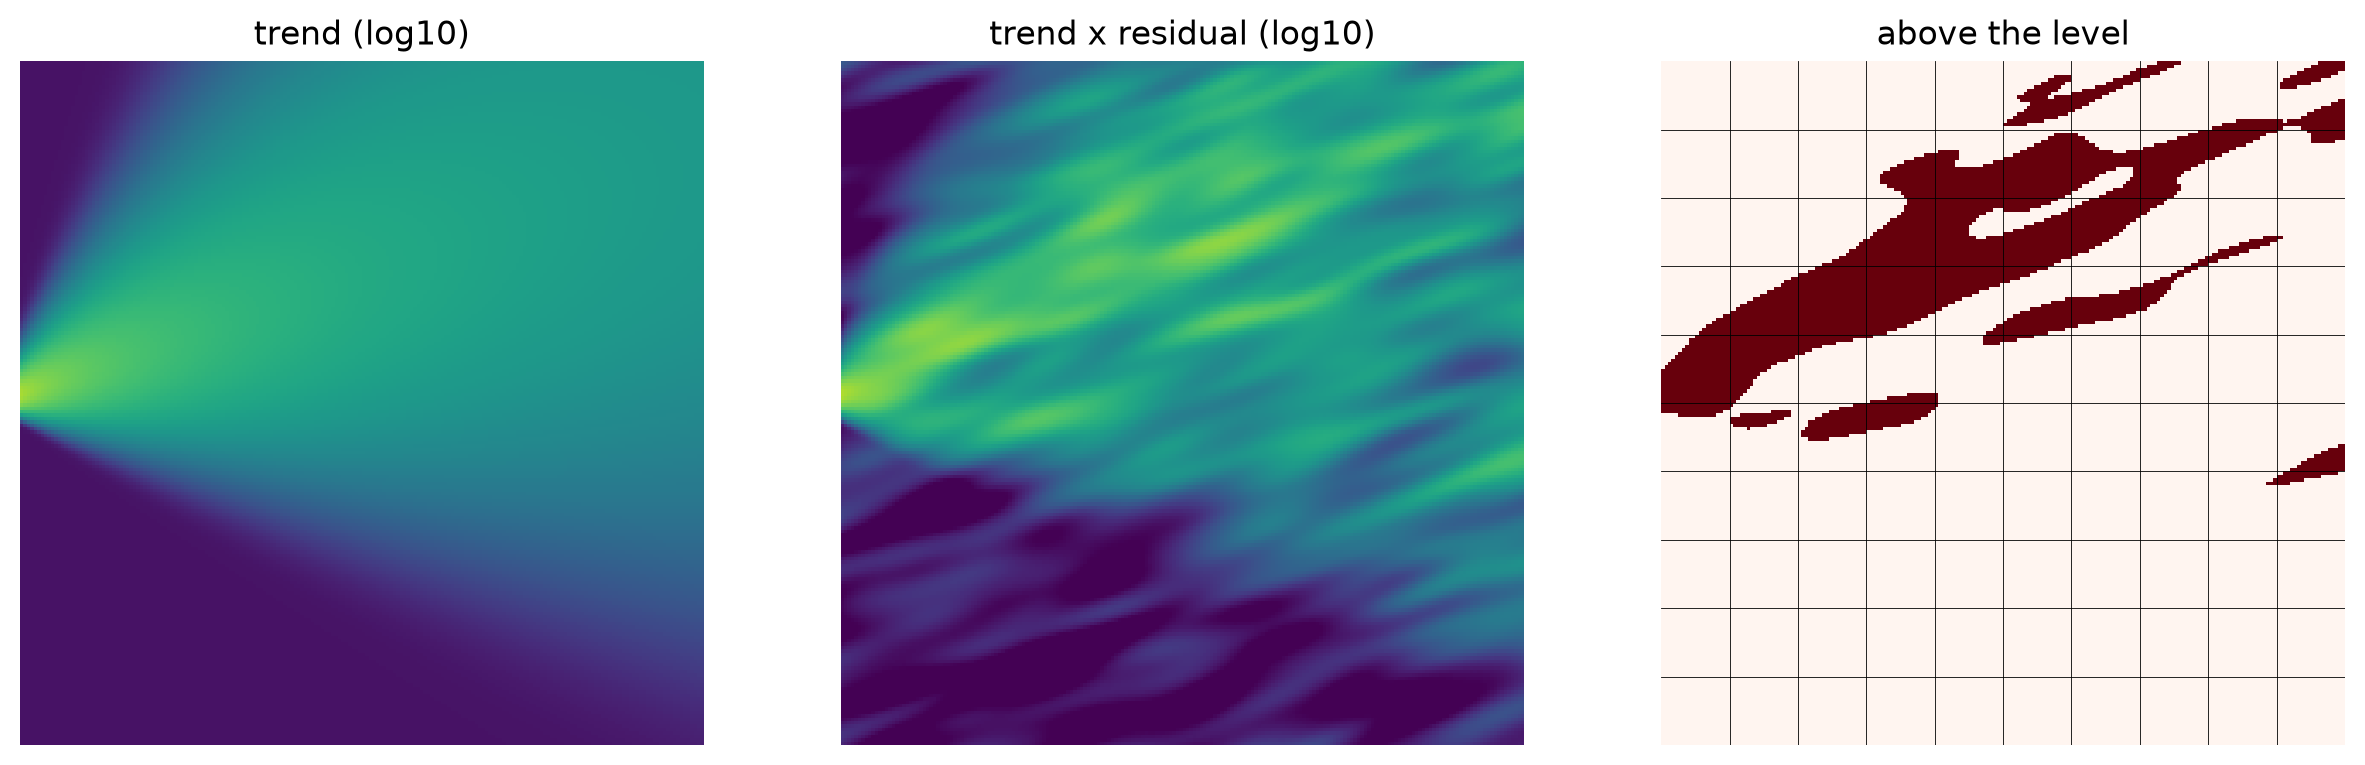

In [ ]:
trend = plume_trend()
plume = plume_field(np.random.default_rng(0))
level = np.quantile(plume, 0.85)
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(np.log10(trend), cmap='viridis', vmin=-1.5, vmax=2.5); axs[0].set_title('trend (log10)')
axs[1].imshow(np.log10(plume), cmap='viridis', vmin=-1.5, vmax=2.5); axs[1].set_title('trend x residual (log10)')
axs[2].imshow(plume > level, cmap='Reds'); axs[2].set_title('above the level')
for k in range(1, 10): axs[2].axhline(k * 20 - 0.5, color='k', lw=0.3); axs[2].axvline(k * 20 - 0.5, color='k', lw=0.3)
for ax in axs: ax.axis('off')

The share of each unit above the level, and the units whose share is between 3% and 30%, where restriction decisions are close:

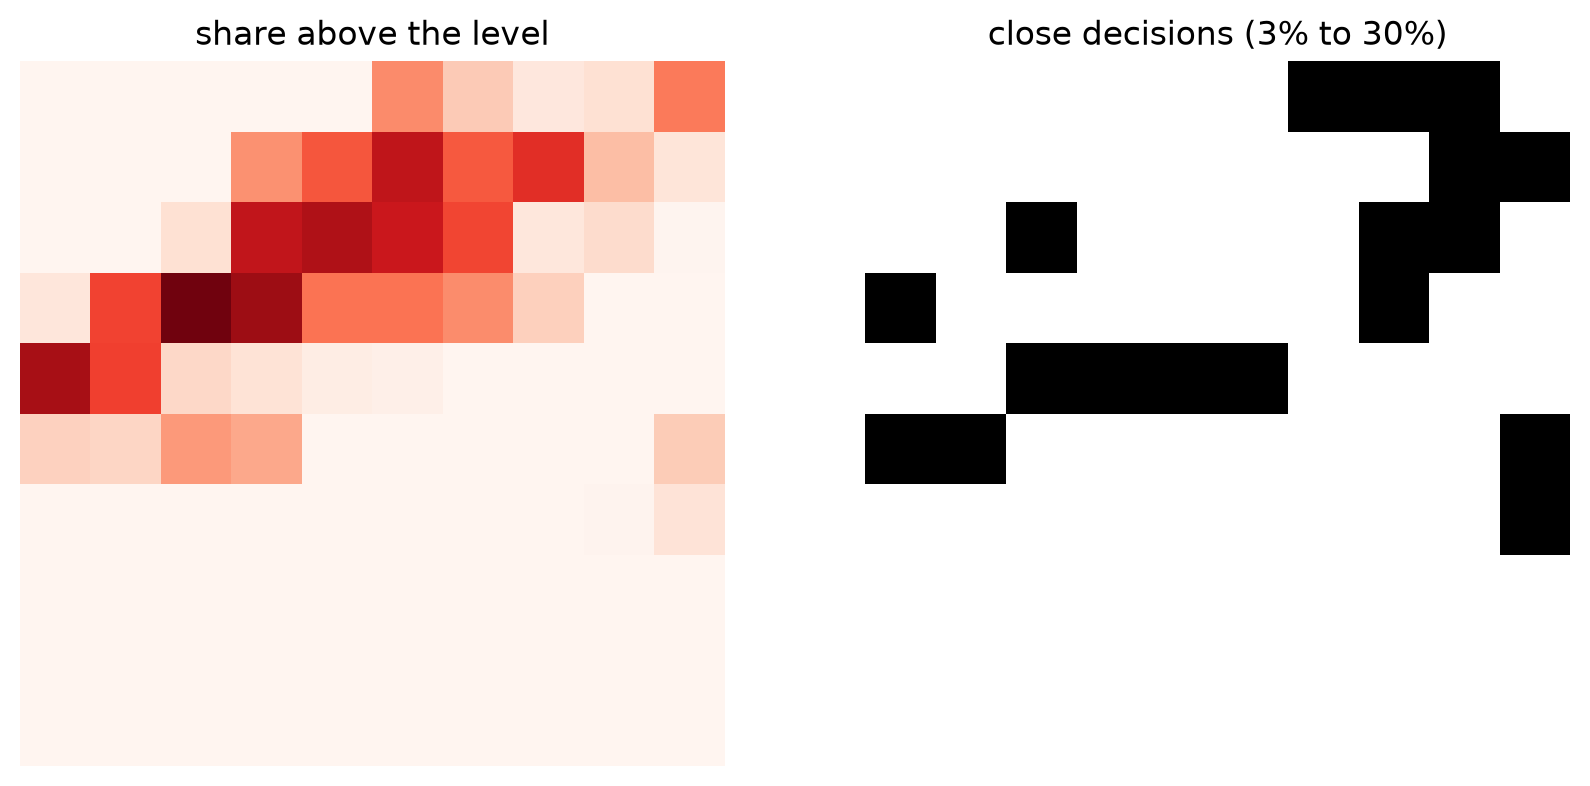

(np.int64(33), np.int64(18))

In [ ]:
unit_share = (plume > level).reshape(10, 20, 10, 20).mean(axis=(1, 3))
close = (unit_share > 0.03) & (unit_share < 0.3)
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(unit_share, cmap='Reds', vmin=0, vmax=1); axs[0].set_title('share above the level')
axs[1].imshow(close, cmap='Greys'); axs[1].set_title('close decisions (3% to 30%)')
for ax in axs: ax.axis('off')
(unit_share > 0.1).sum(), close.sum()

33 of the 100 units should be restricted, and 18 have close decisions. The close units lie along both edges of the plume and in its far end to the north-east, where the residual patches decide whether a unit crosses 10%. Deep inside the plume and far outside it, every decision is clear. A prior that shows where the edge is tells `voi` where the close units are.

A dispersion model gives the trend before any survey flies, so it could serve as `voi`'s prior. In "A synthetic plume" in `_scoring_experiments.ipynb`, on this field with 6 rounds of 150 samples and 40 seeds, `voi` made 5.0 wrong decisions with the dispersion trend as a prior worth 4 samples, against 5.8 with no prior and 6.2 for equal allocation. With the wind 10° off, the gain disappeared (5.7). With the prior worth 20 samples, it made 9.1 wrong decisions, worse than equal allocation: the trend has the plume's shape but not its patches. A survey prior did best of the realistic priors, with 4.1 to 4.4.

## What this means for trufl

- Placement within a unit is a choice as important as the number of samples per unit, once the field is correlated. Stratified placement costs no extra samples, and is the safer default.
- The binomial model behind `bayes` and `voi` is exact for random placement, cautious for spread placement and overconfident for clustered placement. Clustered placement is the dangerous case in practice: many samples, little information, and errors that are mostly missed restrictions.
- Taking placement into account in `voi` would mean an effective sample count per unit, set by the placement and by the range compared with the unit size.
- When the range is long, the exceedances form patches. That makes "partially restrict" meaningful, and placing extra samples near the first exceedances a way to map the patch.
- A plume makes the correlation directional. Strata stretched along the plume gain over square strata when the direction is well known. Along the wrong axis they lose most of the gain, so use square strata when the direction is uncertain.
- A plume also has a trend, and decisions are close only along its edges. A dispersion model gives that trend before a survey, and is worth a small prior weight in `voi`. A unit cut by the plume edge is the clearest case for "partially restrict".

`scoring-design.md` records these as proposals under "Placement within a unit", which includes "Directional fields and plumes".